# 03 · One-hot encoding and the Bag-of-Words model

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/hentablihamza/practical-nlp-course/blob/main/notebooks/03_one_hot_and_bag_of_words.ipynb)

*Practical NLP — a hands-on course in classical natural language processing · Notebook 3 of 12*

Machine-learning algorithms work with **vectors of numbers**, not with words. This notebook introduces
the two oldest and simplest ways to turn text into vectors: **one-hot encoding** for words and the
**Bag-of-Words (BoW)** model for documents. They are simple — and still surprisingly strong baselines.

### Learning objectives
By the end of this notebook you will be able to:
1. Build a vocabulary and one-hot encode words by hand.
2. Represent documents as Bag-of-Words count vectors, by hand and with scikit-learn's `CountVectorizer`.
3. Read and control a vocabulary (`min_df`, `max_df`, `max_features`, binary counts).
4. Explain **sparsity** and why sparse matrices are essential.
5. List the limitations of BoW that motivate TF-IDF and word embeddings.

## 0 · Setup

In [1]:
# Setup — works in Google Colab and locally.
# In Colab: installs missing packages and clones the course repo (for its cached data).
# Locally / in CI: uses the files already in data/ (NLP_OFFLINE=1 forbids any download).
import os, sys, subprocess
from pathlib import Path

if "google.colab" in sys.modules:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "nltk>=3.9", "scikit-learn"], check=True)
    if not Path("practical-nlp-course").exists():
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/hentablihamza/practical-nlp-course.git"], check=True)
    os.chdir("practical-nlp-course/notebooks")

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import nlp_course
nlp_course.setup_nltk()

import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.max_colwidth", 120)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
DOCS = ROOT / "docs"
DOCS.mkdir(exist_ok=True)
print("Offline mode:", nlp_course.OFFLINE)
print("Cached data:", sorted(p.name for p in (ROOT / "data").iterdir() if p.suffix in {".gz", ".json"}))

Offline mode: True
Cached data: ['20newsgroups_4cat.csv.gz', 'provenance.json', 'sms_spam.csv.gz']


In [2]:
from collections import Counter
from sklearn.feature_extraction.text import CountVectorizer

## 1 · A toy corpus
We start with four tiny "documents" so that every number can be checked by eye.

In [3]:
toy = [
    "the rocket reached orbit",
    "the pitcher threw the ball",
    "the rocket launch was delayed",
    "the ball reached the pitcher",
]
for i, d in enumerate(toy):
    print(f"d{i}: {d}")

d0: the rocket reached orbit
d1: the pitcher threw the ball
d2: the rocket launch was delayed
d3: the ball reached the pitcher


## 2 · The vocabulary
The **vocabulary** is the list of distinct words in the corpus. We give each word an index.

In [4]:
vocab = sorted({w for d in toy for w in d.split()})
word2idx = {w: i for i, w in enumerate(vocab)}
print(f"|V| = {len(vocab)} words")
word2idx

|V| = 10 words


{'ball': 0,
 'delayed': 1,
 'launch': 2,
 'orbit': 3,
 'pitcher': 4,
 'reached': 5,
 'rocket': 6,
 'the': 7,
 'threw': 8,
 'was': 9}

## 3 · One-hot encoding of words
In **one-hot encoding**, each word is a vector as long as the vocabulary, full of zeros except a single
1 at the word's index.

$$\text{rocket} = [0, 0, \dots, 0, \underbrace{1}_{\text{index of rocket}}, 0, \dots, 0]$$

In [5]:
def one_hot(word):
    v = np.zeros(len(vocab), dtype=int)
    v[word2idx[word]] = 1
    return v

one_hots = pd.DataFrame(np.eye(len(vocab), dtype=int), index=vocab, columns=vocab)
one_hots

,ball,delayed,launch,orbit,pitcher,reached,rocket,the,threw,was
ball,1,0,0,0,0,0,0,0,0,0
delayed,0,1,0,0,0,0,0,0,0,0
launch,0,0,1,0,0,0,0,0,0,0
orbit,0,0,0,1,0,0,0,0,0,0
pitcher,0,0,0,0,1,0,0,0,0,0
reached,0,0,0,0,0,1,0,0,0,0
rocket,0,0,0,0,0,0,1,0,0,0
the,0,0,0,0,0,0,0,1,0,0
threw,0,0,0,0,0,0,0,0,1,0
was,0,0,0,0,0,0,0,0,0,1


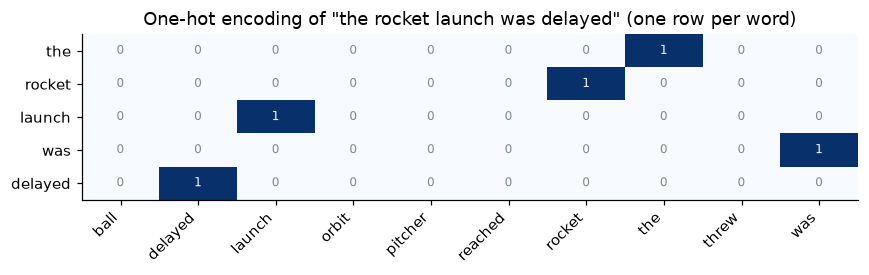

In [6]:
sentence = toy[2].split()
M = np.array([one_hot(w) for w in sentence])
fig, ax = plt.subplots(figsize=(8, 2.6))
ax.imshow(M, cmap="Blues", aspect="auto")
ax.set_xticks(range(len(vocab))); ax.set_xticklabels(vocab, rotation=45, ha="right")
ax.set_yticks(range(len(sentence))); ax.set_yticklabels(sentence)
for i in range(M.shape[0]):
    for j in range(M.shape[1]):
        ax.text(j, i, M[i, j], ha="center", va="center", fontsize=8, color="white" if M[i, j] else "#7f8c8d")
ax.set_title(f'One-hot encoding of "{toy[2]}" (one row per word)')
plt.tight_layout(); plt.savefig(DOCS / "03_one_hot.png", bbox_inches="tight"); plt.show()

### The problem with one-hot vectors: every word is equally different
The dot product (and the cosine similarity) between any two different one-hot vectors is **0**. So
*rocket* is exactly as similar to *launch* as it is to *ball*. One-hot vectors carry **identity**, not
**meaning**.

In [7]:
pairs = [("rocket", "launch"), ("rocket", "ball"), ("pitcher", "ball"), ("rocket", "rocket")]
for a, b in pairs:
    print(f"{a:>8} · {b:<8} = {one_hot(a) @ one_hot(b)}")

  rocket · launch   = 0
  rocket · ball     = 0
 pitcher · ball     = 0
  rocket · rocket   = 1


Learning vectors where *rocket* is close to *launch* is the goal of word embeddings (notebooks 08–09).

## 4 · Bag-of-Words: from words to documents
A **Bag-of-Words** vector represents a whole document by **counting** how many times each vocabulary
word occurs in it. Equivalently, it is the **sum of the one-hot vectors** of its words. Grammar and
word order are thrown away — the document becomes a "bag" of words.

In [8]:
def bow(doc):
    return sum(one_hot(w) for w in doc.split())

X_manual = np.array([bow(d) for d in toy])
pd.DataFrame(X_manual, index=[f"d{i}" for i in range(len(toy))], columns=vocab)

,ball,delayed,launch,orbit,pitcher,reached,rocket,the,threw,was
d0,0,0,0,1,0,1,1,1,0,0
d1,1,0,0,0,1,0,0,2,1,0
d2,0,1,1,0,0,0,1,1,0,1
d3,1,0,0,0,1,1,0,2,0,0


Row `d1` has `the = 2` because *"the pitcher threw **the** ball"* contains *the* twice. This table is
called a **document–term matrix**: one row per document, one column per vocabulary word.

## 5 · `CountVectorizer` — Bag-of-Words in scikit-learn
`CountVectorizer` does all of this for you: it tokenizes, builds the vocabulary (`fit`) and produces
the document–term matrix (`transform`).

In [9]:
cv = CountVectorizer()
X = cv.fit_transform(toy)
print(type(X))
print("shape:", X.shape)
print("vocabulary_:", cv.vocabulary_)
pd.DataFrame(X.toarray(), index=[f"d{i}" for i in range(len(toy))], columns=cv.get_feature_names_out())

<class 'scipy.sparse._csr.csr_matrix'>
shape: (4, 10)
vocabulary_: {'the': 7, 'rocket': 6, 'reached': 5, 'orbit': 3, 'pitcher': 4, 'threw': 8, 'ball': 0, 'launch': 2, 'was': 9, 'delayed': 1}


,ball,delayed,launch,orbit,pitcher,reached,rocket,the,threw,was
d0,0,0,0,1,0,1,1,1,0,0
d1,1,0,0,0,1,0,0,2,1,0
d2,0,1,1,0,0,0,1,1,0,1
d3,1,0,0,0,1,1,0,2,0,0


In [10]:
assert (X.toarray() == X_manual).all() and list(cv.get_feature_names_out()) == vocab
print("CountVectorizer gives exactly the matrix we built by hand.")

CountVectorizer gives exactly the matrix we built by hand.


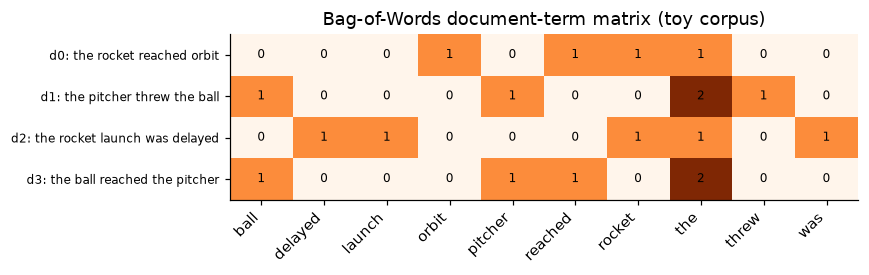

In [11]:
fig, ax = plt.subplots(figsize=(8, 2.6))
A = X.toarray()
ax.imshow(A, cmap="Oranges", aspect="auto")
ax.set_xticks(range(len(vocab))); ax.set_xticklabels(vocab, rotation=45, ha="right")
ax.set_yticks(range(len(toy))); ax.set_yticklabels([f"d{i}: {d}" for i, d in enumerate(toy)], fontsize=8)
for i in range(A.shape[0]):
    for j in range(A.shape[1]):
        ax.text(j, i, A[i, j], ha="center", va="center", fontsize=8)
ax.set_title("Bag-of-Words document-term matrix (toy corpus)")
plt.tight_layout(); plt.savefig(DOCS / "03_bow_toy.png", bbox_inches="tight"); plt.show()

### Useful options
- `binary=True` — record presence (1) or absence (0) instead of counts ("set of words").
- `stop_words="english"` — drop scikit-learn's built-in stopword list.
- `lowercase=True` (the default) and `token_pattern` — control tokenization.
- `analyzer=` — pass your own function, e.g. our `preprocess()` from notebook 02.

In [12]:
cv_bin = CountVectorizer(binary=True, stop_words="english")
Xb = cv_bin.fit_transform(toy)
pd.DataFrame(Xb.toarray(), index=[f"d{i}" for i in range(len(toy))], columns=cv_bin.get_feature_names_out())

,ball,delayed,launch,orbit,pitcher,reached,rocket,threw
d0,0,0,0,1,0,1,1,0
d1,1,0,0,0,1,0,0,1
d2,0,1,1,0,0,0,1,0
d3,1,0,0,0,1,1,0,0


### Unseen words are ignored
The vocabulary is fixed when you call `fit`. A new document is transformed with that vocabulary, and
words never seen during `fit` (*out-of-vocabulary* words) silently disappear.

In [13]:
new = ["the astronaut reached the rocket", "a completely new sentence"]
pd.DataFrame(cv.transform(new).toarray(), index=new, columns=cv.get_feature_names_out())

,ball,delayed,launch,orbit,pitcher,reached,rocket,the,threw,was
the astronaut reached the rocket,0,0,0,0,0,1,1,2,0,0
a completely new sentence,0,0,0,0,0,0,0,0,0,0


*astronaut* is lost, and the second sentence becomes an all-zero vector: the model sees nothing.

### Word order is lost
Two sentences with opposite meanings can have **identical** BoW vectors:

In [14]:
a, b = "the dog bit the man", "the man bit the dog"
va, vb = CountVectorizer().fit([a, b]).transform([a, b]).toarray()
print(a, "->", va)
print(b, "->", vb)
print("identical vectors:", (va == vb).all())

the dog bit the man -> [1 1 1 2]
the man bit the dog -> [1 1 1 2]
identical vectors: True


## 6 · Bag-of-Words on a real corpus
Now the 20 Newsgroups training set (2,239 posts, 4 topics). We plug in the `preprocess()` function
from notebook 02 through the `analyzer` argument, so the vocabulary is made of clean lemmas.

In [15]:
df = nlp_course.load_newsgroups()
train = df[df["subset"] == "train"].reset_index(drop=True)
test = df[df["subset"] == "test"].reset_index(drop=True)

cv = CountVectorizer(analyzer=nlp_course.preprocess)
X_train = cv.fit_transform(train["text"])
n_docs, n_terms = X_train.shape
print(f"document-term matrix: {n_docs:,} documents x {n_terms:,} terms")
print(f"first terms: {list(cv.get_feature_names_out()[:10])}")
print(f"some terms:  {list(cv.get_feature_names_out()[5000:5010])}")

document-term matrix: 2,239 documents x 18,073 terms
first terms: ['aa', 'aaa', 'aaaaaaaaaaaa', 'aammmaaaazzzzzziinnnnggggg', 'aan', 'aangeboden', 'aangegeven', 'aantal', 'aao', 'aaplay']
some terms:  ['emphasize', 'emphatically', 'emphaticaly', 'empire', 'empirical', 'empirically', 'employ', 'employee', 'employer', 'employment']


### Sparsity
Each post uses only a tiny fraction of the vocabulary, so almost every cell in the matrix is zero.
scikit-learn stores it as a **sparse** (CSR) matrix that keeps only the non-zero entries.

In [16]:
nnz = X_train.nnz
density = nnz / (n_docs * n_terms)
dense_mb = n_docs * n_terms * 8 / 1e6           # float64 / int64
sparse_mb = (X_train.data.nbytes + X_train.indices.nbytes + X_train.indptr.nbytes) / 1e6
print(f"non-zero entries: {nnz:,}")
print(f"density: {density:.4%}   ->   sparsity: {1 - density:.2%}")
print(f"average distinct terms per document: {nnz / n_docs:.1f}")
print(f"memory if stored dense : {dense_mb:,.1f} MB")
print(f"memory as sparse CSR   : {sparse_mb:,.2f} MB")

non-zero entries: 135,961
density: 0.3360%   ->   sparsity: 99.66%
average distinct terms per document: 60.7
memory if stored dense : 323.7 MB
memory as sparse CSR   : 1.64 MB


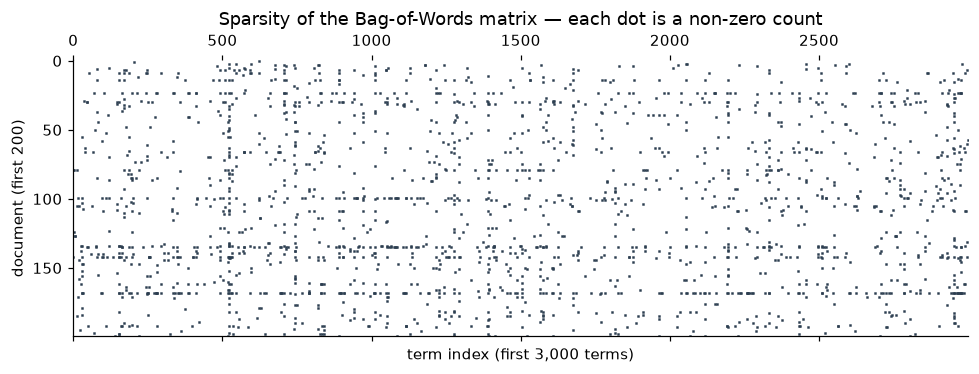

In [17]:
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.spy(X_train[:200, :3000], markersize=0.6, aspect="auto", color="#2c3e50")
ax.set_xlabel("term index (first 3,000 terms)"); ax.set_ylabel("document (first 200)")
ax.set_title("Sparsity of the Bag-of-Words matrix — each dot is a non-zero count")
plt.tight_layout(); plt.savefig(DOCS / "03_sparsity.png", bbox_inches="tight"); plt.show()

### What do the counts tell us about each topic?
Summing the BoW vectors of all documents in a category gives the most frequent words of that topic.

In [18]:
terms = cv.get_feature_names_out()
top = {}
for cat in sorted(train["category"].unique()):
    mask = (train["category"] == cat).to_numpy()
    totals = np.asarray(X_train[mask].sum(axis=0)).ravel()
    idx = totals.argsort()[::-1][:12]
    top[cat] = [f"{terms[i]} ({totals[i]})" for i in idx]
pd.DataFrame(top)

,comp.graphics,rec.sport.baseball,sci.space,talk.politics.misc
0,image (745),year (405),space (987),people (500)
1,file (483),game (354),launch (398),say (487)
2,use (453),get (286),would (370),would (484)
3,graphic (428),team (270),nasa (328),go (471)
4,program (346),run (247),use (301),think (447)
5,jpeg (270),think (245),get (295),make (438)
6,format (258),would (228),one (291),mr (433)
7,get (241),one (223),satellite (287),president (425)
8,color (237),player (218),year (277),get (376)
9,also (232),go (212),system (266),know (350)


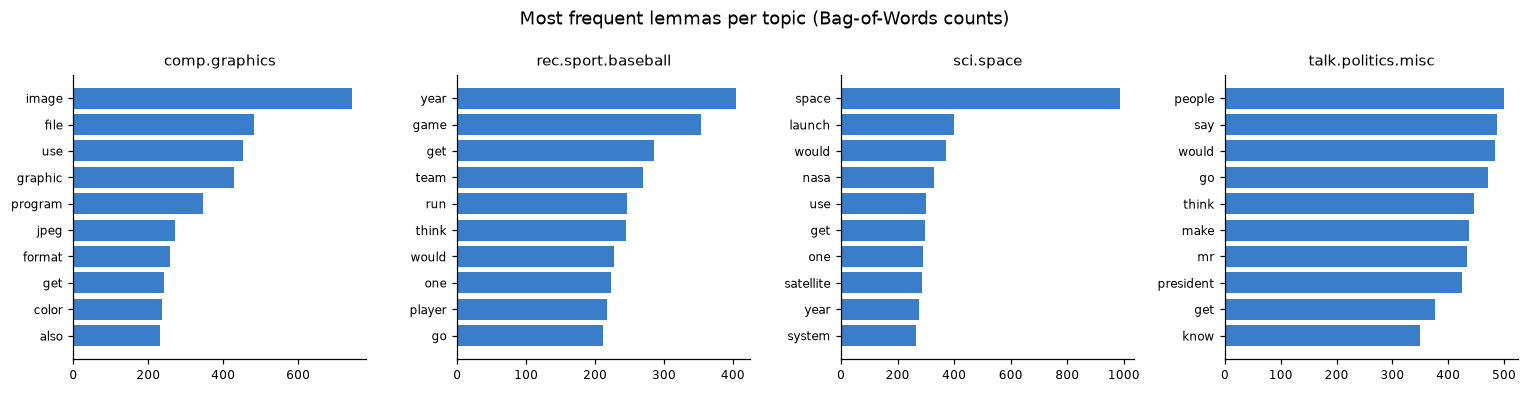

In [19]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3.6))
for ax, cat in zip(axes, sorted(train["category"].unique())):
    mask = (train["category"] == cat).to_numpy()
    totals = np.asarray(X_train[mask].sum(axis=0)).ravel()
    idx = totals.argsort()[::-1][:10][::-1]
    ax.barh(terms[idx], totals[idx], color="#3a7dc9")
    ax.set_title(cat, fontsize=10); ax.tick_params(labelsize=8)
fig.suptitle("Most frequent lemmas per topic (Bag-of-Words counts)")
plt.tight_layout(); plt.savefig(DOCS / "03_top_words_per_category.png", bbox_inches="tight"); plt.show()

The topics are already visible from raw counts: *space, launch, orbit, nasa* vs *game, team, year*
vs *image, file, graphic* vs *people, president, mr*. But generic words such as *would*,
*get* and *one* rank high in **every** topic — raw counts reward words for being frequent, not for
being *distinctive*. Fixing that is the job of TF-IDF in notebook 04.

### Controlling the vocabulary size
Most of the vocabulary is made of rare words (Zipf's law). `min_df` drops words that occur in too few
documents, `max_df` drops words that occur in too many, and `max_features` keeps only the most
frequent terms.

In [20]:
tokenized = [nlp_course.preprocess(t) for t in train["text"]]   # preprocess once, reuse below
identity = lambda tokens: tokens

settings = [
    {},
    {"min_df": 2},
    {"min_df": 5},
    {"min_df": 5, "max_df": 0.5},
    {"max_features": 1000},
]
rows = []
for kw in settings:
    Xk = CountVectorizer(analyzer=identity, **kw).fit_transform(tokenized)
    rows.append({"settings": str(kw) if kw else "default", "terms": Xk.shape[1],
                 "density": f"{Xk.nnz / (Xk.shape[0] * Xk.shape[1]):.3%}",
                 "empty docs": int((Xk.sum(axis=1) == 0).sum())})
pd.DataFrame(rows).set_index("settings")

,terms,density,empty docs
settings,,,
default,18073,0.336%,70
{'min_df': 2},9013,0.629%,72
{'min_df': 5},4400,1.164%,79
"{'min_df': 5, 'max_df': 0.5}",4400,1.164%,79
{'max_features': 1000},1000,3.353%,88


In [21]:
doc_freq = np.asarray((X_train > 0).sum(axis=0)).ravel()
print(f"terms that appear in only 1 document: {(doc_freq == 1).sum():,} of {n_terms:,} "
      f"({(doc_freq == 1).mean():.1%})")
print("terms that appear in more than 20% of documents:",
      sorted(terms[doc_freq > 0.2 * n_docs]))

terms that appear in only 1 document: 9,060 of 18,073 (50.1%)
terms that appear in more than 20% of documents: ['get', 'know', 'like', 'one', 'think', 'use', 'would']


Requiring a word to appear in at least 2 documents halves the vocabulary, because half of all terms
occur in a single post. `max_df=0.5` changes nothing here — after stopword removal no lemma appears in
more than half of the posts (the most widespread ones are listed above). Note the price of an aggressive
cut: more documents end up with an all-zero vector.

### Transforming the test set
We **fit** the vocabulary on the training set only, then **transform** the test set with it — exactly
as a deployed model would see new documents. Words that never appeared in training are dropped.

In [22]:
X_test = cv.transform(test["text"])
test_tokens = [tok for t in test["text"] for tok in nlp_course.preprocess(t)]
vocab_set = set(cv.vocabulary_)
oov = [t for t in test_tokens if t not in vocab_set]
print("test matrix:", X_test.shape)
print(f"test tokens: {len(test_tokens):,}, out-of-vocabulary: {len(oov):,} ({len(oov) / len(test_tokens):.1%})")
print("most common OOV words:", Counter(oov).most_common(10))

test matrix: (1490, 18073)
test tokens: 161,520, out-of-vocabulary: 7,196 (4.5%)
most common OOV words: [('hirschbeck', 35), ('reisman', 29), ('davidians', 22), ('nok', 22), ('grenade', 20), ('manchester', 20), ('deviant', 17), ('celsius', 17), ('uvesa', 16), ('fc', 16)]


## 7 · Limitations of Bag-of-Words

| Limitation | Example | Addressed by |
|---|---|---|
| **No word order** | *dog bit man* = *man bit dog* | n-grams (notebook 05) |
| **Frequent words dominate** | *would*, *get* top every topic | TF-IDF (notebook 04) |
| **No meaning / similarity between words** | *rocket* ⟂ *launch*, *car* ⟂ *automobile* | word2vec, GloVe (notebooks 08–09) |
| **Huge, sparse vectors** | ~18,000 dimensions, >99% zeros | `min_df`, LSA (notebook 07), embeddings |
| **Out-of-vocabulary words** | *astronaut* disappears | larger corpora, subwords (beyond this course) |

Despite all this, Bag-of-Words + a linear classifier is a strong, fast baseline for text classification
— we will measure exactly how strong in notebook 10.

## 8 · Exercises

**Exercise 1.** Use `CountVectorizer(ngram_range=(1, 2))` on the toy corpus. How many features are
there now, and do *"the dog bit the man"* and *"the man bit the dog"* still get identical vectors?

In [23]:
# your code here

<details>
<summary><b>Show solution</b></summary>

Bigrams such as `dog bit` and `man bit` restore some word order, so the vectors differ.

```python
cv12 = CountVectorizer(ngram_range=(1, 2)).fit(toy)
print("features with unigrams + bigrams:", len(cv12.get_feature_names_out()))
cv_dog = CountVectorizer(ngram_range=(1, 2)).fit([a, b])
va, vb = cv_dog.transform([a, b]).toarray()
print({t: (int(x), int(y)) for t, x, y in zip(cv_dog.get_feature_names_out(), va, vb)})
print("identical:", (va == vb).all())
```
</details>

In [24]:
cv12 = CountVectorizer(ngram_range=(1, 2)).fit(toy)
print("features with unigrams + bigrams:", len(cv12.get_feature_names_out()))
cv_dog = CountVectorizer(ngram_range=(1, 2)).fit([a, b])
va, vb = cv_dog.transform([a, b]).toarray()
print({t: (int(x), int(y)) for t, x, y in zip(cv_dog.get_feature_names_out(), va, vb)})
print("identical:", (va == vb).all())

features with unigrams + bigrams: 22
{'bit': (1, 1), 'bit the': (1, 1), 'dog': (1, 1), 'dog bit': (1, 0), 'man': (1, 1), 'man bit': (0, 1), 'the': (2, 2), 'the dog': (1, 1), 'the man': (1, 1)}
identical: False


**Exercise 2.** Build a Bag-of-Words matrix for the **SMS Spam Collection** with the default
`CountVectorizer`. Report its shape, its sparsity and the average number of distinct words per message.
Compare with the newsgroups matrix.

In [25]:
# your code here

<details>
<summary><b>Show solution</b></summary>

SMS messages are much shorter, so each row has even fewer non-zeros.

```python
sms = nlp_course.load_sms()
X_sms = CountVectorizer().fit_transform(sms["text"])
print("shape:", X_sms.shape)
print(f"sparsity: {1 - X_sms.nnz / (X_sms.shape[0] * X_sms.shape[1]):.3%}")
print(f"distinct words per message: {X_sms.nnz / X_sms.shape[0]:.1f}")
```
</details>

In [26]:
sms = nlp_course.load_sms()
X_sms = CountVectorizer().fit_transform(sms["text"])
print("shape:", X_sms.shape)
print(f"sparsity: {1 - X_sms.nnz / (X_sms.shape[0] * X_sms.shape[1]):.3%}")
print(f"distinct words per message: {X_sms.nnz / X_sms.shape[0]:.1f}")

shape: (5574, 8713)
sparsity: 99.847%
distinct words per message: 13.3


**Exercise 3.** Using `X_train` and `terms`, find the 10 words that are most *specific* to
`sci.space`: the words with the highest ratio of (count in sci.space + 1) / (count in the other three
topics + 1), among words that occur at least 20 times in sci.space. Why do these look more informative
than the plain top-count words?

In [27]:
# your code here

<details>
<summary><b>Show solution</b></summary>

Dividing by the frequency elsewhere rewards words that are *distinctive* for a topic rather than merely frequent — the same intuition behind the IDF part of TF-IDF.

```python
mask = (train["category"] == "sci.space").to_numpy()
in_space = np.asarray(X_train[mask].sum(axis=0)).ravel()
elsewhere = np.asarray(X_train[~mask].sum(axis=0)).ravel()
ratio = (in_space + 1) / (elsewhere + 1)
ok = in_space >= 20
best = np.argsort(np.where(ok, ratio, 0))[::-1][:10]
pd.DataFrame({"term": terms[best], "in sci.space": in_space[best], "elsewhere": elsewhere[best],
              "ratio": ratio[best].round(1)})
```
</details>

In [28]:
mask = (train["category"] == "sci.space").to_numpy()
in_space = np.asarray(X_train[mask].sum(axis=0)).ravel()
elsewhere = np.asarray(X_train[~mask].sum(axis=0)).ravel()
ratio = (in_space + 1) / (elsewhere + 1)
ok = in_space >= 20
best = np.argsort(np.where(ok, ratio, 0))[::-1][:10]
pd.DataFrame({"term": terms[best], "in sci.space": in_space[best], "elsewhere": elsewhere[best],
              "ratio": ratio[best].round(1)})

,term,in sci.space,elsewhere,ratio
0,lunar,182,0,183.0
1,spacecraft,119,0,120.0
2,orbit,262,2,87.7
3,orbital,76,0,77.0
4,km,69,0,70.0
5,orbiter,65,0,66.0
6,astronaut,63,0,64.0
7,sky,52,0,53.0
8,larson,52,0,53.0
9,saturn,51,0,52.0


## Summary
- A **vocabulary** maps each distinct word to an index; a **one-hot** vector marks one word.
- One-hot vectors are all orthogonal: they encode identity, not meaning.
- A **Bag-of-Words** vector counts words in a document (the sum of its one-hot vectors); stacking them
  gives the **document–term matrix**. `CountVectorizer` builds it in one line.
- Real BoW matrices are extremely **sparse**, so they are stored in sparse formats.
- BoW ignores word order and meaning, and lets frequent words dominate.

**Next:** [04 · Term weighting](04_tf_and_tfidf.ipynb) — from raw counts to TF and **TF-IDF**.